In [1]:
import marimo as mo

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [3]:
from kaggle_api import fetch_dataset

df_train, df_test = fetch_dataset()

cols_categorical = "x4 x5 x10 Y".split()
df_train["Y"] = df_train["Y"].astype("category")
for df in (df_train, df_test):
    for _col in cols_categorical[:-1]:
        df[_col] = df[_col].astype("category")
    df["x1a"] = (df.x1 >= 0).astype(np.int8).astype("category")

✅ data loaded!


In [4]:
df_train.columns

Index(['x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7', 'x8', 'x9', 'x10', 'Y',
       'x1a'],
      dtype='str')

# model overview

- type - LDA

In [5]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis as QDA

In [6]:
lda = LDA(store_covariance = True)
model = lda.fit(df_train.drop("Y", axis=1), df_train.Y)

In [7]:
prediction = model.predict_proba(df_test)

prediction_probs = pd.Series(prediction[:, 1], index=df_test.index)

prediction_probs.describe()

count    10000.000000
mean         0.279337
std          0.148142
min          0.042677
25%          0.137829
50%          0.262064
75%          0.415252
max          0.657586
dtype: float64

# model assessment

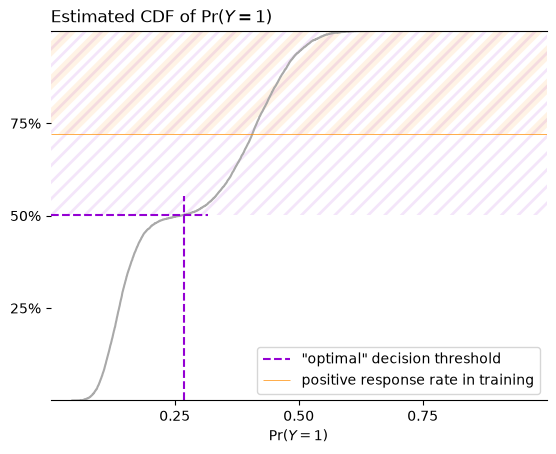

In [8]:
import threshold as th

pos_prediction_count, threshold = th.estimate_optimal_threshold(prediction_probs)

mo.output.append(pos_prediction_count)
mo.output.append(threshold)

mo.output.append(
    th.plot_probs(
        probs=prediction_probs,
        expt_prob=np.mean(df_train.Y.astype(np.int64)),
        threshold=threshold,
        pos_pred_count=pos_prediction_count,
    )
)

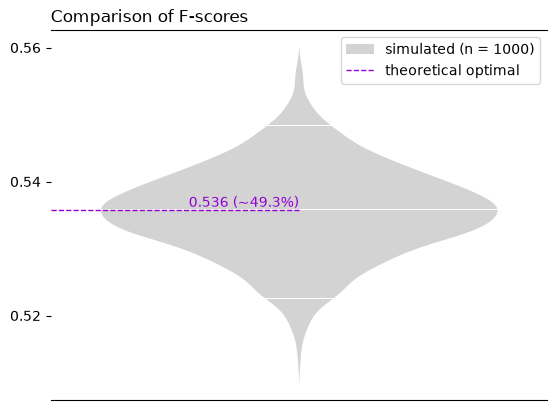

In [9]:
rng = np.random.default_rng(1)

_ = th.plot_f_scores(
    empiricals=th.sample_probable_f_scores(
        rng, 1000, prediction_probs, pos_prediction_count
    ),
    calculated=2 * threshold,
    reported=None,
)

# make submission

In [10]:
predictions = prediction_probs.sort_values(ascending=False)
predictions.iloc[0:pos_prediction_count] = 1
predictions.iloc[pos_prediction_count:] = 0
predictions = predictions.astype(np.int8).sort_index()

predictions

ID
15001    0
15002    1
15003    1
15004    0
15005    0
        ..
24996    1
24997    1
24998    0
24999    0
25000    0
Length: 10000, dtype: int8

In [11]:
import os
import os.path
import pathlib

notebook_path = os.environ.get("JPY_SESSION_NAME")
submission_filepath = pathlib.Path(
    f"./submissions/{os.path.splitext(os.path.basename(notebook_path))[0]}.csv"
)
print(f"saving submission file to {submission_filepath}")
predictions.to_csv(submission_filepath)

saving submission file to submissions/model3_LDA.csv
